In [1]:
from google.colab import files

uploaded = files.upload()

Saving sales_data.csv to sales_data.csv


In [2]:
import os

print(os.listdir("/content"))

['.config', 'sales_data.csv', 'sample_data']


In [3]:
import os

print(os.listdir("/content"))


['.config', 'sales_data.csv', '.ipynb_checkpoints']


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("/content/sales_data.csv")

# Display basic information
print("Dataset loaded successfully!")
print("Shape (rows, columns):", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

# Display first 5 rows
display(df.head())

Dataset loaded successfully!
Shape (rows, columns): (76000, 16)

Column names:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality', 'Epidemic', 'Demand']


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [5]:
# Remove the Demand column
df = df.drop(columns=["Demand"])

# Check the result
print("Dataset shape after removing Demand:", df.shape)

print("\nRemaining columns:")
print(df.columns.tolist())


Dataset shape after removing Demand: (76000, 15)

Remaining columns:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality', 'Epidemic']


In [6]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
dtype: int64

Total missing values: 0

Duplicate rows: 0


In [7]:
# Convert Date into datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Display date range
print("Starting date:", df["Date"].min())
print("Ending date:", df["Date"].max())

# Check invalid dates
print("Invalid dates:", df["Date"].isna().sum())


Starting date: 2022-01-01 00:00:00
Ending date: 2024-01-30 00:00:00
Invalid dates: 0


In [8]:
print("Number of stores:", df["Store ID"].nunique())
print("Number of products:", df["Product ID"].nunique())

print("\nProducts per category:")
print(df["Category"].value_counts())

print("\nSales statistics:")
print(df["Units Sold"].describe())

Number of stores: 5
Number of products: 20

Products per category:
Category
Groceries      30400
Furniture      13680
Clothing       12160
Toys           10640
Electronics     9120
Name: count, dtype: int64

Sales statistics:
count    76000.000000
mean        88.827316
std         43.994525
min          0.000000
25%         58.000000
50%         84.000000
75%        114.000000
max        426.000000
Name: Units Sold, dtype: float64


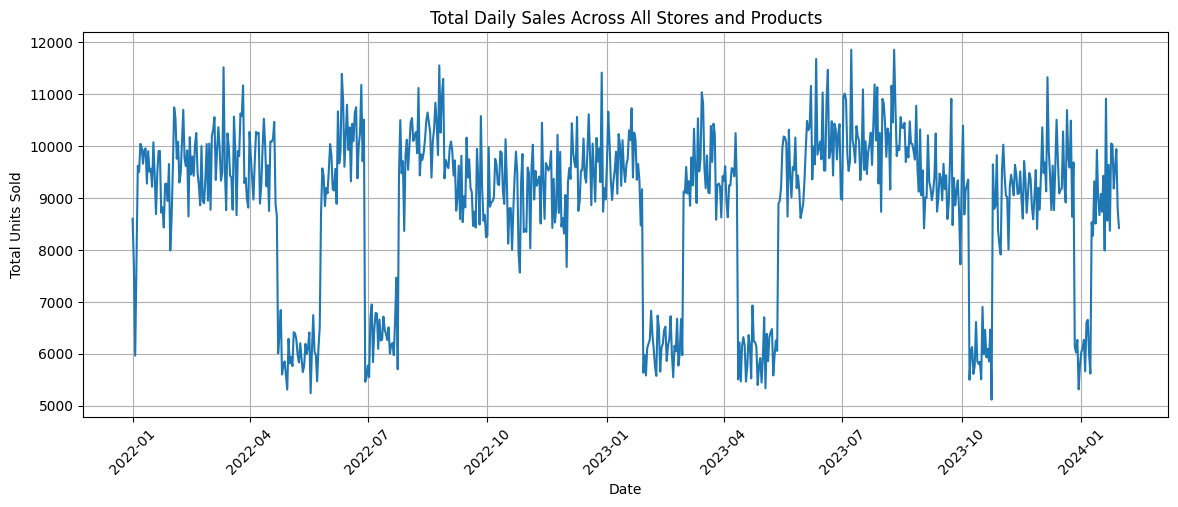

In [9]:
import matplotlib.pyplot as plt

# Calculate total sales for each date
daily_sales = (
    df.groupby("Date")["Units Sold"]
      .sum()
      .sort_index()
)

# Plot sales
plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)

plt.title("Total Daily Sales Across All Stores and Products")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()


In [47]:
# Step 22 debug: Define the corrected order list builder that returns 'out'
def build_order_list_corrected(forecast, rec, lead_time_days):
    f = forecast.sort_values(keys + ["horizon"]).copy()
    f["cum_demand"] = f.groupby(keys)["predicted_units"].cumsum()
    f = f.merge(rec[keys + ["current_stock"]], on=keys, how="left")
    runs_out = (f[f["cum_demand"] >= f["current_stock"]]
                .groupby(keys)["horizon"].min()
                .rename("runs_out_on_day").reset_index())
    out = rec.merge(runs_out, on=keys, how="left")

    def priority(row):
        if row["reorder_qty"] == 0:
            return "OK"
        if pd.notna(row["runs_out_on_day"]) and row["runs_out_on_day"] <= lead_time_days:
            return "URGENT"
        return "ORDER"

    out["priority"] = out.apply(priority, axis=1)
    out["stock_lasts"] = out["runs_out_on_day"].apply(
        lambda d: "more than 14 days" if pd.isna(d) else "about " + str(int(d)) + " day(s)")
    return out

# 1. Run validation comparing corrected function to notebook Step 20
ol_v1 = build_order_list_corrected(fc_file, rec, LEAD_TIME_DAYS)
cmp = ol_v1.merge(order[keys + ["priority"]], on=keys, suffixes=("_module", "_notebook"))
print("Priorities identical to Step 20:",
      bool((cmp["priority_module"] == cmp["priority_notebook"]).all()), "| rows:", len(cmp))

# 2. Build priorities with the per-product buffers (Version 2)
ol_v2 = build_order_list_corrected(fc_file, rec2_file, LEAD_TIME_DAYS)
print("\nPriorities with per-product buffers (Version 2):")
print(ol_v2["priority"].value_counts())
print("Total units to order under Version 2:", ol_v2["reorder_qty"].sum())

Priorities identical to Step 20: True | rows: 100

Priorities with per-product buffers (Version 2):
priority
URGENT    56
OK        29
ORDER     15
Name: count, dtype: int64
Total units to order under Version 2: 11751


In [ ]:
# Overwrite the buggy forecaster.py module with the corrected implementation
with open("/content/saved_model/forecaster.py", "w") as f:
    f.write("""# Feature building and forecasting for the demand forecaster
import numpy as np
import pandas as pd
import joblib

KEYS = [\"Store ID\", \"Product ID\"]


def load_bundle(path):
    # Loads the saved model together with its settings
    return joblib.load(path)


def make_forecast(history, future_plan, bundle, origin_date):
    # history: columns Store ID, Product ID, Date, Units Sold (sales up to the origin date)
    # future_plan: columns Store ID, Product ID, Date, Price, Discount, Promotion (no sales)
    model = bundle[\"model\"]
    features = bundle[\"features\"]
    max_h = bundle[\"max_horizon\"]
    origin_date = pd.Timestamp(origin_date)

    # 1. Use only sales up to and including the origin date
    hist = history[history[\"Date\"] <= origin_date].sort_values(KEYS + [\"Date\"])

    # 2. Last 7 rows of every store-product combination
    last7 = hist.groupby(KEYS).tail(7)
    origin_feats = last7.groupby(KEYS).agg(
        lag_6=(\"Units Sold\", \"first\"),
        lag_0=(\"Units Sold\", \"last\"),
        avg_7=(\"Units Sold\", \"mean\"),
        first_date=(\"Date\", \"min\"),
        last_date=(\"Date\", \"max\"),
    ).reset_index()

    # 3. Safety check: 7 consecutive days ending exactly on the origin date
    span = (origin_feats[\"last_date\"] - origin_feats[\"first_date\"]).dt.days
    if not ((origin_feats[\"last_date\"] == origin_date).all() and (span == 6).all()):
        raise ValueError(\"History is incomplete around the origin date\")

    # 4. One row per store-product per future day
    plan = future_plan[
        (future_plan[\"Date\"] > origin_date)
        & (future_plan[\"Date\"] <= origin_date + pd.Timedelta(days=max_h))
    ].copy()
    plan[\"horizon\"] = (plan[\"Date\"] - origin_date).dt.days
    plan[\"target_dow\"] = plan[\"Date\"].dt.dayofweek
    rows = plan.merge(origin_feats[KEYS + [\"lag_0\", \"lag_6\", \"avg_7\"]], on=KEYS, how=\"left\")

    # 5. Predict directly for every horizon (sales cannot be negative)
    rows[\"predicted_units\"] = np.clip(model.predict(rows[features]), 0, None)
    return rows


def recommend_restock(forecast, current_stock, lead_time_days, z, daily_error, on_order=0):
    # forecast: output of make_forecast (needs Store ID, Product ID, horizon, predicted_units)
    # current_stock: table with Store ID, Product ID, current_stock
    if lead_time_days > forecast[\"horizon\"].max():
        raise ValueError(\"Lead time is longer than the forecast horizon\")

    # Lead-time demand = forecast units for days 1..lead_time_days
    window = forecast[forecast[\"horizon\"] <= lead_time_days]
    demand = (window.groupby(KEYS)[\"predicted_units\"]
                    .sum().rename(\"lead_time_demand\").reset_index())

    out = demand.merge(current_stock, on=KEYS, how=\"left\")
    out[\"safety_stock\"] = z * daily_error * np.sqrt(lead_time_days)
    out[\"on_order\"] = on_order
    need = out[\"lead_time_demand\"] + out[\"safety_stock\"] - out[\"current_stock\"] - out[\"on_order\"]
    out[\"reorder_qty\"] = np.ceil(np.clip(need, 0, None)).astype(int)
    return out


def recommend_restock_v2(forecast, current_stock, lead_time_days, z, error_table,
                         default_error, on_order=0):
    # error_table: Store ID, Product ID, daily_error (forecast error per store-product)
    if lead_time_days > forecast[\"horizon\"].max():
        raise ValueError(\"Lead time is longer than the forecast horizon\")
    window = forecast[forecast[\"horizon\"] <= lead_time_days]
    demand = (window.groupby(KEYS)[\"predicted_units\"]
                    .sum().rename(\"lead_time_demand\").reset_index())
    out = demand.merge(current_stock, on=KEYS, how=\"left\")
    out = out.merge(error_table, on=KEYS, how=\"left\")
    out[\"daily_error\"] = out[\"daily_error\"].fillna(default_error)
    out[\"safety_stock\"] = z * out[\"daily_error\"] * np.sqrt(lead_time_days)
    out[\"on_order\"] = on_order
    need = out[\"lead_time_demand\"] + out[\"safety_stock\"] - out[\"current_stock\"] - out[\"on_order\"]
    out[\"reorder_qty\"] = np.ceil(np.clip(need, 0, None)).astype(int)
    return out


def build_order_list(forecast, rec, lead_time_days):
    # Adds runs_out_on_day, stock_lasts and priority (URGENT / ORDER / OK) to a restock table
    f = forecast.sort_values(KEYS + [\"horizon\"]).copy()
    f[\"cum_demand\"] = f.groupby(KEYS)[\"predicted_units\"].cumsum()
    f = f.merge(rec[KEYS + [\"current_stock\"]], on=KEYS, how=\"left\")
    runs_out = (f[f[\"cum_demand\"] >= f[\"current_stock\"]]
                .groupby(KEYS)[\"horizon\"].min()
                .rename(\"runs_out_on_day\").reset_index())
    out = rec.merge(runs_out, on=KEYS, how=\"left\")

    def priority(row):
        if row[\"reorder_qty\"] == 0:
            return \"OK\"
        if pd.notna(row[\"runs_out_on_day\"]) and row[\"runs_out_on_day\"] <= lead_time_days:
            return \"URGENT\"
        return \"ORDER\"

    out[\"priority\"] = out.apply(priority, axis=1)
    out[\"stock_lasts\"] = out[\"runs_out_on_day\"].apply(
        lambda d: \"more than 14 days\" if pd.isna(d) else \"about \" + str(int(d)) + \" day(s)\")
    return out
""")

# Sync module with Google Drive backup folder
import shutil, os
shutil.copy("/content/saved_model/forecaster.py", "/content/drive/MyDrive/ML_stockAdvisor_backup/forecaster.py")
print("Saved local file size:", os.path.getsize("/content/saved_model/forecaster.py"), "bytes")
print("Saved backup file size:", os.path.getsize("/content/drive/MyDrive/ML_stockAdvisor_backup/forecaster.py"), "bytes")

# Reload module & run official test validation to verify error is fixed
import importlib
importlib.reload(forecaster)

ol_v1 = forecaster.build_order_list(fc_file, rec, LEAD_TIME_DAYS)
cmp = ol_v1.merge(order[keys + ["priority"]], on=keys, suffixes=("_module", "_notebook"))
print("Fixed Module validation priorities match Notebook Step 20 exactly:",
      bool((cmp["priority_module"] == cmp["priority_notebook"]).all()))

In [15]:
# Sort the dataset by store, product, and date
df = df.sort_values(
    ["Store ID", "Product ID", "Date"]
).copy()

# Create historical sales features for each store-product combination
grouped_sales = df.groupby(["Store ID", "Product ID"])["Units Sold"]

# Sales from the previous recorded day
df["sales_lag_1"] = grouped_sales.shift(1)

# Sales from seven recorded days earlier
df["sales_lag_7"] = grouped_sales.shift(7)

# Average sales over the previous seven recorded days
df["sales_avg_7"] = (
    df.groupby(["Store ID", "Product ID"])["Units Sold"]
      .transform(lambda s: s.shift(1).rolling(7).mean())
)

# Display the new features
display(
    df[[
        "Date",
        "Store ID",
        "Product ID",
        "Units Sold",
        "sales_lag_1",
        "sales_lag_7",
        "sales_avg_7"
    ]].head(15)
)

,Date,Store ID,Product ID,Units Sold,sales_lag_1,sales_lag_7,sales_avg_7
0,2022-01-01,S001,P0001,102,NaN,NaN,NaN
100,2022-01-02,S001,P0001,71,102.0,NaN,NaN
200,2022-01-03,S001,P0001,142,71.0,NaN,NaN
300,2022-01-04,S001,P0001,42,142.0,NaN,NaN
400,2022-01-05,S001,P0001,129,42.0,NaN,NaN
500,2022-01-06,S001,P0001,98,129.0,NaN,NaN
600,2022-01-07,S001,P0001,92,98.0,NaN,NaN
700,2022-01-08,S001,P0001,96,92.0,102.0,96.571429
800,2022-01-09,S001,P0001,57,96.0,71.0,95.714286
900,2022-01-10,S001,P0001,88,57.0,142.0,93.714286


In [16]:
# Check missing values in historical features
print("Missing values in each feature:")

print(
    df[[
        "sales_lag_1",
        "sales_lag_7",
        "sales_avg_7"
    ]].isnull().sum()
)

# Check total number of rows
print("\nTotal rows:", len(df))

Missing values in each feature:
sales_lag_1    100
sales_lag_7    700
sales_avg_7    700
dtype: int64

Total rows: 76000


In [17]:
# Step 1: verify that every store-product combination has a complete daily history

# 1. How many unique dates exist in the whole dataset?
all_dates = pd.date_range(df["Date"].min(), df["Date"].max(), freq="D")
print("First date:", df["Date"].min().date())
print("Last date :", df["Date"].max().date())
print("Days in the full calendar range:", len(all_dates))
print("Unique dates actually present  :", df["Date"].nunique())

# 2. For each store-product combination, count rows and find first/last date
combo_summary = (
    df.groupby(["Store ID", "Product ID"])["Date"]
      .agg(rows="count", first_date="min", last_date="max", unique_dates="nunique")
)

print()
print("Number of store-product combinations:", len(combo_summary))
print("Distinct row counts across combinations:", combo_summary["rows"].unique())
print("Distinct first dates:", combo_summary["first_date"].dt.date.unique())
print("Distinct last dates :", combo_summary["last_date"].dt.date.unique())

# 3. Look for repeated dates inside any combination
duplicate_dates = df.duplicated(subset=["Store ID", "Product ID", "Date"]).sum()
print()
print("Repeated (store, product, date) rows:", duplicate_dates)

# 4. Look for gaps: the difference between consecutive dates should always be 1 day
day_gaps = df.groupby(["Store ID", "Product ID"])["Date"].diff().dt.days
print()
print("Day gaps between consecutive rows (value counts):")
print(day_gaps.value_counts(dropna=False))


First date: 2022-01-01
Last date : 2024-01-30
Days in the full calendar range: 760
Unique dates actually present  : 760

Number of store-product combinations: 100
Distinct row counts across combinations: [760]
Distinct first dates: [datetime.date(2022, 1, 1)]
Distinct last dates : [datetime.date(2024, 1, 30)]

Repeated (store, product, date) rows: 0

Day gaps between consecutive rows (value counts):
Date
1.0    75900
NaN      100
Name: count, dtype: int64


In [18]:
# Step 2: build the modeling dataset and split it chronologically

# 1. Add a weekday feature (0 = Monday, 6 = Sunday); it is known for any future date
df["day_of_week"] = df["Date"].dt.dayofweek

# 2. Define features and target
feature_columns = [
    "sales_lag_1",
    "sales_lag_7",
    "sales_avg_7",
    "Price",
    "Discount",
    "Promotion",
    "day_of_week",
]
target_column = "Units Sold"

# 3. Keep only rows where all lag features exist
model_df = df.dropna(subset=["sales_lag_1", "sales_lag_7", "sales_avg_7"]).copy()

# 4. Chronological split using date boundaries
train_end = pd.Timestamp("2023-09-30")
val_end = pd.Timestamp("2023-11-30")

train_df = model_df[model_df["Date"] <= train_end]
val_df = model_df[(model_df["Date"] > train_end) & (model_df["Date"] <= val_end)]
test_df = model_df[model_df["Date"] > val_end]

# 5. Inspect the result
print("Modeling dataset shape:", model_df.shape)
print()
for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(name, "rows:", len(part),
          "| dates:", part["Date"].min().date(), "to", part["Date"].max().date(),
          "| days:", part["Date"].nunique())

print()
print("Data types of the features:")
print(model_df[feature_columns].dtypes)

print()
print("Any missing values left in features/target?")
print(model_df[feature_columns + [target_column]].isna().sum())

Modeling dataset shape: (75300, 19)

Train rows: 63100 | dates: 2022-01-08 to 2023-09-30 | days: 631
Validation rows: 6100 | dates: 2023-10-01 to 2023-11-30 | days: 61
Test rows: 6100 | dates: 2023-12-01 to 2024-01-30 | days: 61

Data types of the features:
sales_lag_1    float64
sales_lag_7    float64
sales_avg_7    float64
Price          float64
Discount         int64
Promotion        int64
day_of_week      int32
dtype: object

Any missing values left in features/target?
sales_lag_1    0
sales_lag_7    0
sales_avg_7    0
Price          0
Discount       0
Promotion      0
day_of_week    0
Units Sold     0
dtype: int64


In [19]:
# Step 3: score the two baselines on the validation period

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Helper function: returns MAE and RMSE for a set of predictions
def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return mae, rmse

# Quick look at the binary-style columns, to be sure we understand them
print("Promotion values:", sorted(model_df["Promotion"].unique()))
print("Discount values :", sorted(model_df["Discount"].unique()))
print()

# The actual values we are trying to predict in the validation period
y_val = val_df[target_column]
print("Average Units Sold in validation:", round(y_val.mean(), 2))
print("Std. deviation of Units Sold in validation:", round(y_val.std(), 2))
print()

# Baseline 1: same weekday last week
mae1, rmse1 = evaluate(y_val, val_df["sales_lag_7"])

# Baseline 2: seven-day moving average
mae2, rmse2 = evaluate(y_val, val_df["sales_avg_7"])

# Collect the results in a small table so we can add more models later
results = pd.DataFrame(
    [
        ["Same weekday last week", mae1, rmse1],
        ["7-day moving average", mae2, rmse2],
    ],
    columns=["Model", "Validation MAE", "Validation RMSE"],
)
print(results.round(3))

Promotion values: [np.int64(0), np.int64(1)]
Discount values : [np.int64(0), np.int64(5), np.int64(10), np.int64(15), np.int64(20), np.int64(25)]

Average Units Sold in validation: 81.94
Std. deviation of Units Sold in validation: 40.87

                    Model  Validation MAE  Validation RMSE
0  Same weekday last week          39.238           50.982
1    7-day moving average          29.463           38.354


In [20]:
# Step 4: train-mean reference and Ridge Regression

from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Separate inputs (X) and target (y) for training and validation
X_train = train_df[feature_columns]
y_train = train_df[target_column]
X_val = val_df[feature_columns]

# 2. Reference: always predict the average of the TRAINING sales
mean_pred = np.full(len(y_val), y_train.mean())
mae0, rmse0 = evaluate(y_val, mean_pred)

# 3. Preprocessing: scale numeric columns, one-hot encode the weekday
numeric_cols = [c for c in feature_columns if c != "day_of_week"]
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("day", OneHotEncoder(handle_unknown="ignore"), ["day_of_week"]),
])

# 4. Pipeline = preprocessing + Ridge model
ridge_model = Pipeline([
    ("prep", preprocess),
    ("model", Ridge(alpha=1.0)),
])

# 5. Learn from the training data only, then predict the validation period
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_val)
mae3, rmse3 = evaluate(y_val, ridge_pred)

# 6. Add the new rows to the results table
new_rows = pd.DataFrame(
    [
        ["Training average (reference)", mae0, rmse0],
        ["Ridge Regression", mae3, rmse3],
    ],
    columns=results.columns,
)
results = pd.concat([results, new_rows], ignore_index=True)
print(results.round(3))

# 7. Which numeric features does Ridge weigh most? (scaled weights, so they are comparable)
weights = ridge_model.named_steps["model"].coef_[:len(numeric_cols)]
print()
print(pd.Series(weights, index=numeric_cols).round(3))

                          Model  Validation MAE  Validation RMSE
0        Same weekday last week          39.238           50.982
1          7-day moving average          29.463           38.354
2  Training average (reference)          33.343           41.598
3              Ridge Regression          28.243           36.472

sales_lag_1    -1.085
sales_lag_7    -1.737
sales_avg_7    21.047
Price           3.594
Discount        1.078
Promotion       9.915
dtype: float64


In [21]:
# Step 5: Random Forest

from sklearn.ensemble import RandomForestRegressor

# 1. Create the model (settings chosen to be fast and to limit overfitting)
rf_model = RandomForestRegressor(
    n_estimators=200,       # number of trees
    max_depth=12,           # how many questions deep each tree can go
    min_samples_leaf=20,    # each final group must contain at least 20 rows
    random_state=42,
    n_jobs=-1,
)

# 2. Learn from the training data only
rf_model.fit(X_train, y_train)

# 3. Predict on both training and validation data
rf_train_pred = rf_model.predict(X_train)
rf_val_pred = rf_model.predict(X_val)

mae_tr, rmse_tr = evaluate(y_train, rf_train_pred)
mae4, rmse4 = evaluate(y_val, rf_val_pred)

print("Random Forest TRAIN MAE:", round(mae_tr, 3), "| RMSE:", round(rmse_tr, 3))
print("Random Forest VALID MAE:", round(mae4, 3), "| RMSE:", round(rmse4, 3))

# 4. Add to the results table
new_row = pd.DataFrame(
    [["Random Forest", mae4, rmse4]],
    columns=results.columns,
)
results = pd.concat([results, new_row], ignore_index=True)
print()
print(results.round(3))

# 5. Which features did the forest use most?
importances = pd.Series(rf_model.feature_importances_, index=feature_columns)
print()
print(importances.sort_values(ascending=False).round(3))

Random Forest TRAIN MAE: 27.331 | RMSE: 35.787
Random Forest VALID MAE: 27.621 | RMSE: 35.874

                          Model  Validation MAE  Validation RMSE
0        Same weekday last week          39.238           50.982
1          7-day moving average          29.463           38.354
2  Training average (reference)          33.343           41.598
3              Ridge Regression          28.243           36.472
4                 Random Forest          27.621           35.874

sales_avg_7    0.570
Promotion      0.165
Price          0.138
sales_lag_1    0.051
sales_lag_7    0.047
day_of_week    0.016
Discount       0.013
dtype: float64


In [22]:
# Step 6: HistGradientBoostingRegressor

from sklearn.ensemble import HistGradientBoostingRegressor

# 1. Create the model
hgb_model = HistGradientBoostingRegressor(
    learning_rate=0.05,        # small, careful correction steps
    max_iter=300,              # maximum number of trees to add
    max_depth=6,               # limit how deep each tree can go
    min_samples_leaf=50,       # each final group must contain at least 50 rows
    early_stopping=True,       # stop adding trees when improvement stalls
    validation_fraction=0.1,   # internal holdout used only for early stopping
    random_state=42,
)

# 2. Learn from the training data only
hgb_model.fit(X_train, y_train)

# 3. Predict and score on training and validation data
hgb_train_pred = hgb_model.predict(X_train)
hgb_val_pred = hgb_model.predict(X_val)

mae_tr2, rmse_tr2 = evaluate(y_train, hgb_train_pred)
mae5, rmse5 = evaluate(y_val, hgb_val_pred)

print("Trees actually used (after early stopping):", hgb_model.n_iter_)
print("HGB TRAIN MAE:", round(mae_tr2, 3), "| RMSE:", round(rmse_tr2, 3))
print("HGB VALID MAE:", round(mae5, 3), "| RMSE:", round(rmse5, 3))

# 4. Add to the results table
new_row = pd.DataFrame(
    [["HistGradientBoosting", mae5, rmse5]],
    columns=results.columns,
)
results = pd.concat([results, new_row], ignore_index=True)
print()
print(results.round(3))

Trees actually used (after early stopping): 119
HGB TRAIN MAE: 28.527 | RMSE: 37.295
HGB VALID MAE: 27.43 | RMSE: 35.659

                          Model  Validation MAE  Validation RMSE
0        Same weekday last week          39.238           50.982
1          7-day moving average          29.463           38.354
2  Training average (reference)          33.343           41.598
3              Ridge Regression          28.243           36.472
4                 Random Forest          27.621           35.874
5          HistGradientBoosting          27.430           35.659


In [23]:
# Step 7: final evaluation of the selected model (HistGradientBoosting) on the test period

# 1. Prepare test inputs and target
X_test = test_df[feature_columns]
y_test = test_df[target_column]

print("Average Units Sold in test:", round(y_test.mean(), 2))
print("Std. deviation of Units Sold in test:", round(y_test.std(), 2))
print()

# 2. Helper for WAPE (error as a percentage of total actual sales)
def wape(y_true, y_pred):
    return np.abs(y_true - y_pred).sum() / np.abs(y_true).sum() * 100

# 3. Predictions from the already-trained model (trained on training data only)
hgb_test_pred = hgb_model.predict(X_test)

# 4. Score the selected model and the reference methods
test_rows = []

mae_t, rmse_t = evaluate(y_test, hgb_test_pred)
test_rows.append(["HistGradientBoosting (selected)", mae_t, rmse_t, wape(y_test, hgb_test_pred)])

mae_b, rmse_b = evaluate(y_test, test_df["sales_avg_7"])
test_rows.append(["7-day moving average", mae_b, rmse_b, wape(y_test, test_df["sales_avg_7"])])

mae_w, rmse_w = evaluate(y_test, test_df["sales_lag_7"])
test_rows.append(["Same weekday last week", mae_w, rmse_w, wape(y_test, test_df["sales_lag_7"])])

train_mean_pred = np.full(len(y_test), y_train.mean())
mae_m, rmse_m = evaluate(y_test, train_mean_pred)
test_rows.append(["Training average (reference)", mae_m, rmse_m, wape(y_test, train_mean_pred)])

test_results = pd.DataFrame(
    test_rows, columns=["Model", "Test MAE", "Test RMSE", "Test WAPE %"]
)
print(test_results.round(3))

# 5. Compare validation and test scores of the selected model
print()
print("HGB validation MAE:", round(mae5, 3), "| RMSE:", round(rmse5, 3))
print("HGB test       MAE:", round(mae_t, 3), "| RMSE:", round(rmse_t, 3))

Average Units Sold in test: 86.89
Std. deviation of Units Sold in test: 43.07

                             Model  Test MAE  Test RMSE  Test WAPE %
0  HistGradientBoosting (selected)    29.087     37.577       33.477
1             7-day moving average    31.640     40.919       36.415
2           Same weekday last week    42.926     55.036       49.405
3     Training average (reference)    34.291     43.160       39.466

HGB validation MAE: 27.43 | RMSE: 35.659
HGB test       MAE: 29.087 | RMSE: 37.577


In [24]:
# Step 8: build the direct multi-horizon dataset

H = 14  # maximum forecast horizon (days ahead)

# 1. Work on a clean, sorted copy with only the columns we need
base = df[["Store ID", "Product ID", "Date", "Units Sold", "Price", "Discount", "Promotion"]].copy()
base = base.sort_values(["Store ID", "Product ID", "Date"]).reset_index(drop=True)
group = base.groupby(["Store ID", "Product ID"])["Units Sold"]

# 2. Features known at the origin day T (built from sales up to and including T)
base["lag_0"] = group.shift(0)                                  # sales on day T
base["lag_6"] = group.shift(6)                                  # sales on day T-6
base["avg_7"] = group.transform(lambda s: s.rolling(7).mean())  # average of T-6 .. T

# 3. For each horizon h, attach the target-day information (T+h)
pieces = []
for h in range(1, H + 1):
    part = base[["Store ID", "Product ID", "Date", "lag_0", "lag_6", "avg_7"]].copy()
    part = part.rename(columns={"Date": "origin_date"})
    part["horizon"] = h

    # Values on the target day = the row h positions later within the same store-product
    g = base.groupby(["Store ID", "Product ID"])
    part["target_date"] = g["Date"].shift(-h)
    part["target_sales"] = g["Units Sold"].shift(-h)
    part["Price"] = g["Price"].shift(-h)
    part["Discount"] = g["Discount"].shift(-h)
    part["Promotion"] = g["Promotion"].shift(-h)
    pieces.append(part)

multi_df = pd.concat(pieces, ignore_index=True)

# 4. Drop rows where lags are missing (start) or the target day does not exist (end)
multi_df = multi_df.dropna().copy()
multi_df["target_dow"] = multi_df["target_date"].dt.dayofweek

# 5. Chronological split by TARGET date, using the same boundaries as before
m_train = multi_df[multi_df["target_date"] <= train_end]
m_val = multi_df[(multi_df["target_date"] > train_end) & (multi_df["target_date"] <= val_end)]
m_test = multi_df[multi_df["target_date"] > val_end]

print("Multi-horizon dataset shape:", multi_df.shape)
print("Train rows:", len(m_train), "| Validation rows:", len(m_val), "| Test rows:", len(m_test))
print()
print("Rows per horizon (should be nearly equal):")
print(multi_df["horizon"].value_counts().sort_index())
print()

# 6. Sanity check on one example row: print its pieces so you can verify by eye
example = multi_df.iloc[1000]
print("Example row:")
print(example)

Multi-horizon dataset shape: (1045100, 13)
Train rows: 874300 | Validation rows: 85400 | Test rows: 85400

Rows per horizon (should be nearly equal):
horizon
1     75300
2     75200
3     75100
4     75000
5     74900
6     74800
7     74700
8     74600
9     74500
10    74400
11    74300
12    74200
13    74100
14    74000
Name: count, dtype: int64

Example row:
Store ID                       S001
Product ID                    P0002
origin_date     2022-09-11 00:00:00
lag_0                            65
lag_6                          77.0
avg_7                     87.714286
horizon                           1
target_date     2022-09-12 00:00:00
target_sales                   69.0
Price                         67.92
Discount                        0.0
Promotion                       0.0
target_dow                        0
Name: 1013, dtype: object


In [25]:
# Step 9: train HistGradientBoosting on the multi-horizon data and score it per horizon

multi_features = [
    "lag_0", "lag_6", "avg_7", "horizon",
    "Price", "Discount", "Promotion", "target_dow",
]

# 1. Inputs and targets for each block
Xm_train, ym_train = m_train[multi_features], m_train["target_sales"]
Xm_val, ym_val = m_val[multi_features], m_val["target_sales"]

# 2. Train the multi-horizon model on training rows only
hgb_multi = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_depth=6,
    min_samples_leaf=50,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42,
)
hgb_multi.fit(Xm_train, ym_train)
print("Trees actually used:", hgb_multi.n_iter_)

# 3. Predict the validation block
mval_pred = hgb_multi.predict(Xm_val)
mae_m1, rmse_m1 = evaluate(ym_val, mval_pred)

# 4. Baseline: 7-day moving average known at the origin day
mae_m2, rmse_m2 = evaluate(ym_val, m_val["avg_7"])

print()
print("Overall validation, horizons 1-14 combined:")
print("HGB multi-horizon   MAE:", round(mae_m1, 3), "| RMSE:", round(rmse_m1, 3))
print("7-day moving average MAE:", round(mae_m2, 3), "| RMSE:", round(rmse_m2, 3))

# 5. Score each horizon separately
rows = []
for h in range(1, H + 1):
    mask = (m_val["horizon"] == h).values
    h_mae_model, _ = evaluate(ym_val[mask], mval_pred[mask])
    h_mae_base, _ = evaluate(ym_val[mask], m_val.loc[mask, "avg_7"])
    rows.append([h, h_mae_model, h_mae_base])

per_h = pd.DataFrame(rows, columns=["Horizon", "HGB MAE", "Moving-avg MAE"])
print()
print(per_h.round(3))

Trees actually used: 300

Overall validation, horizons 1-14 combined:
HGB multi-horizon   MAE: 29.465 | RMSE: 37.836
7-day moving average MAE: 32.573 | RMSE: 41.752

    Horizon  HGB MAE  Moving-avg MAE
0         1   27.416          29.463
1         2   27.632          29.808
2         3   27.920          30.188
3         4   28.361          30.766
4         5   28.698          31.281
5         6   29.151          31.832
6         7   29.383          32.201
7         8   29.676          32.726
8         9   29.960          33.363
9        10   30.316          33.916
10       11   30.584          34.319
11       12   30.826          34.952
12       13   31.111          35.389
13       14   31.484          35.824


    Trees  Validation MAE  Validation RMSE
0      50          29.789           38.027
1     100          29.568           37.879
2     150          29.501           37.836
3     200          29.473           37.817
4     250          29.459           37.808
5     300          29.447           37.795
6     350          29.440           37.789
7     400          29.431           37.779
8     450          29.427           37.777
9     500          29.435           37.786
10    550          29.442           37.792
11    600          29.432           37.785


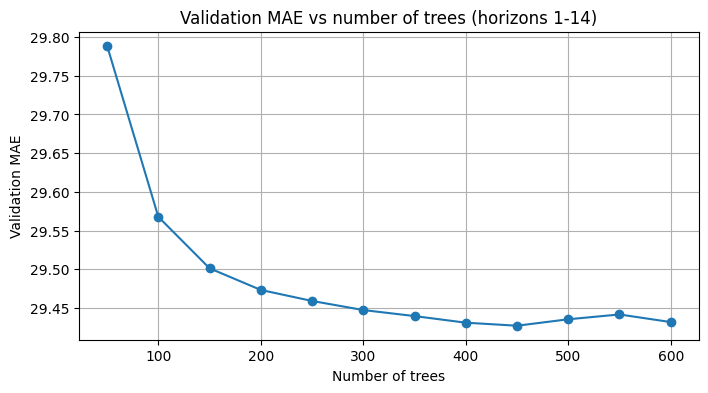

In [26]:
# Step 10: find a good number of trees using the chronological validation block

# 1. Same settings as before, but more trees and NO internal early stopping
hgb_long = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=600,
    max_depth=6,
    min_samples_leaf=50,
    early_stopping=False,
    random_state=42,
)
hgb_long.fit(Xm_train, ym_train)

# 2. Validation MAE and RMSE after every 50 trees
stage_rows = []
for i, stage_pred in enumerate(hgb_long.staged_predict(Xm_val), start=1):
    if i % 50 == 0:
        mae_s, rmse_s = evaluate(ym_val, stage_pred)
        stage_rows.append([i, mae_s, rmse_s])

stage_table = pd.DataFrame(stage_rows, columns=["Trees", "Validation MAE", "Validation RMSE"])
print(stage_table.round(3))

# 3. Plot validation MAE against number of trees
plt.figure(figsize=(8, 4))
plt.plot(stage_table["Trees"], stage_table["Validation MAE"], marker="o")
plt.title("Validation MAE vs number of trees (horizons 1-14)")
plt.xlabel("Number of trees")
plt.ylabel("Validation MAE")
plt.grid(True)
plt.show()

In [29]:
# Step 11: final multi-horizon evaluation on the test period

# 1. Final settings chosen from the validation experiment (400 trees, no early stopping)
hgb_final = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=400,
    max_depth=6,
    min_samples_leaf=50,
    early_stopping=False,
    random_state=42,
)
hgb_final.fit(Xm_train, ym_train)

# 2. Prepare the test inputs and targets
Xm_test, ym_test = m_test[multi_features], m_test["target_sales"]
mtest_pred = hgb_final.predict(Xm_test)

# 3. Overall test scores for the model and the moving-average baseline
mae_a, rmse_a = evaluate(ym_test, mtest_pred)
mae_b2, rmse_b2 = evaluate(ym_test, m_test["avg_7"])

print("Average Units Sold in test:", round(ym_test.mean(), 2))
print()
print("Overall test, horizons 1-14 combined:")
print("HGB multi-horizon    MAE:", round(mae_a, 3), "| RMSE:", round(rmse_a, 3),
      "| WAPE %:", round(wape(ym_test, mtest_pred), 2))
print("7-day moving average MAE:", round(mae_b2, 3), "| RMSE:", round(rmse_b2, 3),
      "| WAPE %:", round(wape(ym_test, m_test["avg_7"]), 2))

# 4. Score each horizon separately
rows = []
for h in range(1, H + 1):
    mask = (m_test["horizon"] == h).values
    h_mae_model, _ = evaluate(ym_test[mask], mtest_pred[mask])
    h_mae_base, _ = evaluate(ym_test[mask], m_test.loc[mask, "avg_7"])
    rows.append([h, h_mae_model, h_mae_base])

per_h_test = pd.DataFrame(rows, columns=["Horizon", "HGB MAE", "Moving-avg MAE"])
print()
print(per_h_test.round(3))

Average Units Sold in test: 86.89

Overall test, horizons 1-14 combined:
HGB multi-horizon    MAE: 31.106 | RMSE: 39.617 | WAPE %: 35.8
7-day moving average MAE: 34.923 | RMSE: 44.286 | WAPE %: 40.19

    Horizon  HGB MAE  Moving-avg MAE
0         1   28.951          31.640
1         2   29.286          32.052
2         3   29.732          32.618
3         4   30.098          33.182
4         5   30.512          33.772
5         6   30.893          34.479
6         7   31.326          35.216
7         8   31.690          35.735
8         9   31.895          36.174
9        10   32.104          36.498
10       11   32.257          36.755
11       12   32.290          36.909
12       13   32.250          36.970
13       14   32.196          36.917


Forecast rows: 1400 (expected 100 x 14 = 1400)
Rows matched: 1400
Largest difference vs Step 8 pipeline: 0.0

Backtest from 2024-01-16 (14 days, all 100 store-products)
HGB forecast         MAE: 28.3 | RMSE: 36.926
7-day moving average MAE: 31.504 | RMSE: 40.755

      Date  horizon  predicted_units  actual_units
2024-01-17        1             90.1          74.0
2024-01-18        2             91.4         149.0
2024-01-19        3             75.7          42.0
2024-01-20        4            108.8         139.0
2024-01-21        5             92.7          84.0
2024-01-22        6             87.3         137.0
2024-01-23        7             81.0          84.0
2024-01-24        8            110.0         135.0
2024-01-25        9             96.4          97.0
2024-01-26       10            109.1          67.0
2024-01-27       11            108.1          78.0
2024-01-28       12             90.0          99.0
2024-01-29       13             78.6          42.0
2024-01-30       14   

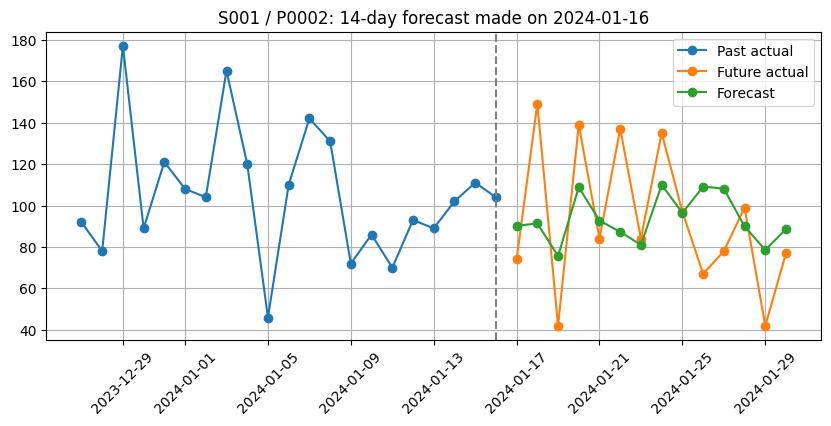

In [30]:
# Step 12: forecasting function and "pretend today" backtest

keys = ["Store ID", "Product ID"]

def make_forecast(history, future_plan, model, origin_date, max_h=14):
    # history: past sales (needs Store ID, Product ID, Date, Units Sold)
    # future_plan: planned Price, Discount, Promotion for future days (no sales)
    origin_date = pd.Timestamp(origin_date)

    # 1. Use only sales up to and including the origin date
    hist = history[history["Date"] <= origin_date].sort_values(keys + ["Date"])

    # 2. Last 7 days of every store-product combination
    last7 = hist.groupby(keys).tail(7)
    origin_feats = last7.groupby(keys).agg(
        lag_6=("Units Sold", "first"),   # sales on day T-6
        lag_0=("Units Sold", "last"),    # sales on day T
        avg_7=("Units Sold", "mean"),    # average of days T-6 .. T
        first_date=("Date", "min"),
        last_date=("Date", "max"),
    ).reset_index()

    # 3. Safety check: 7 consecutive days ending exactly on the origin date
    span = (origin_feats["last_date"] - origin_feats["first_date"]).dt.days
    if not ((origin_feats["last_date"] == origin_date).all() and (span == 6).all()):
        raise ValueError("History is incomplete around the origin date")

    # 4. One row per store-product per future day; horizon = days after the origin
    plan = future_plan[
        (future_plan["Date"] > origin_date)
        & (future_plan["Date"] <= origin_date + pd.Timedelta(days=max_h))
    ].copy()
    plan["horizon"] = (plan["Date"] - origin_date).dt.days
    plan["target_dow"] = plan["Date"].dt.dayofweek
    rows = plan.merge(origin_feats[keys + ["lag_0", "lag_6", "avg_7"]], on=keys, how="left")

    # 5. Predict directly for every horizon (sales cannot be negative)
    rows["predicted_units"] = np.clip(model.predict(rows[multi_features]), 0, None)
    return rows


# ---------- Backtest: pretend today is 2024-01-16 ----------
origin = pd.Timestamp("2024-01-16")

# The function only receives sales up to the origin date
history = df.loc[df["Date"] <= origin, keys + ["Date", "Units Sold"]]

# The plan contains Price, Discount, Promotion only, with no sales columns
future_plan = df.loc[df["Date"] > origin, keys + ["Date", "Price", "Discount", "Promotion"]]

fc = make_forecast(history, future_plan, hgb_final, origin, max_h=14)
print("Forecast rows:", len(fc), "(expected 100 x 14 = 1400)")

# Consistency check against the Step 8 dataset for the same origin date
ref = m_test[m_test["origin_date"] == origin].copy()
ref["ref_pred"] = np.clip(hgb_final.predict(ref[multi_features]), 0, None)
check = fc.merge(ref[keys + ["horizon", "ref_pred", "target_sales"]], on=keys + ["horizon"])
print("Rows matched:", len(check))
print("Largest difference vs Step 8 pipeline:",
      (check["predicted_units"] - check["ref_pred"]).abs().max())

# Score the backtest against the true sales
mae_f, rmse_f = evaluate(check["target_sales"], check["predicted_units"])
mae_g, rmse_g = evaluate(check["target_sales"], check["avg_7"])
print()
print("Backtest from 2024-01-16 (14 days, all 100 store-products)")
print("HGB forecast         MAE:", round(mae_f, 3), "| RMSE:", round(rmse_f, 3))
print("7-day moving average MAE:", round(mae_g, 3), "| RMSE:", round(rmse_g, 3))

# Look at one store-product in detail
one = check[(check["Store ID"] == "S001") & (check["Product ID"] == "P0002")].sort_values("horizon")
print()
print(one[["Date", "horizon", "predicted_units", "target_sales"]]
      .rename(columns={"target_sales": "actual_units"}).round(1).to_string(index=False))

# Plot: last 21 known days, then forecast vs actual
past = df[(df["Store ID"] == "S001") & (df["Product ID"] == "P0002")
          & (df["Date"] <= origin) & (df["Date"] > origin - pd.Timedelta(days=21))]
plt.figure(figsize=(10, 4))
plt.plot(past["Date"], past["Units Sold"], marker="o", label="Past actual")
plt.plot(one["Date"], one["target_sales"], marker="o", label="Future actual")
plt.plot(one["Date"], one["predicted_units"], marker="o", label="Forecast")
plt.axvline(origin, color="gray", linestyle="--")
plt.title("S001 / P0002: 14-day forecast made on 2024-01-16")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

In [31]:
# Re-print the key numbers from Step 12 without recomputing the forecast
print("Forecast rows:", len(fc))
print("Rows matched:", len(check))
print("Largest difference vs Step 8 pipeline:",
      (check["predicted_units"] - check["ref_pred"]).abs().max())
print("HGB forecast         MAE:", round(mae_f, 3), "| RMSE:", round(rmse_f, 3))
print("7-day moving average MAE:", round(mae_g, 3), "| RMSE:", round(rmse_g, 3))

Forecast rows: 1400
Rows matched: 1400
Largest difference vs Step 8 pipeline: 0.0
HGB forecast         MAE: 28.3 | RMSE: 36.926
7-day moving average MAE: 31.504 | RMSE: 40.755


In [32]:
# Step 13: train the deployment model on all available data, save it, reload it, and verify it

import joblib
import os

# 1. All rows of the multi-horizon dataset (train + validation + test)
X_all = multi_df[multi_features]
y_all = multi_df["target_sales"]
print("Rows used for the deployment model:", len(X_all))

# 2. Same settings as the evaluation model (nothing re-tuned)
hgb_deploy = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=400,
    max_depth=6,
    min_samples_leaf=50,
    early_stopping=False,
    random_state=42,
)
hgb_deploy.fit(X_all, y_all)

# 3. Bundle the model with the information needed to use it correctly
bundle = {
    "model": hgb_deploy,
    "features": multi_features,
    "max_horizon": H,
    "keys": keys,
    "trained_target_dates": (str(multi_df["target_date"].min().date()),
                             str(multi_df["target_date"].max().date())),
    "notes": "Direct multi-horizon HistGradientBoosting. Needs 7 consecutive days of history "
             "and planned Price, Discount, Promotion for the future days.",
}

# 4. Save to a file
os.makedirs("/content/saved_model", exist_ok=True)
model_path = "/content/saved_model/demand_forecaster.joblib"
joblib.dump(bundle, model_path)
print("Saved file size (MB):", round(os.path.getsize(model_path) / 1e6, 2))

# 5. Round-trip test: load the file and compare its predictions with the in-memory model
loaded = joblib.load(model_path)
sample = m_test[multi_features].head(5000)
pred_memory = hgb_deploy.predict(sample)
pred_loaded = loaded["model"].predict(sample)
print("Largest difference (in memory vs loaded):", np.abs(pred_memory - pred_loaded).max())
print("Features stored:", loaded["features"])
print("Trained on target dates:", loaded["trained_target_dates"])

Rows used for the deployment model: 1045100
Saved file size (MB): 1.45
Largest difference (in memory vs loaded): 0.0
Features stored: ['lag_0', 'lag_6', 'avg_7', 'horizon', 'Price', 'Discount', 'Promotion', 'target_dow']
Trained on target dates: ('2022-01-08', '2024-01-30')


In [33]:
%%writefile /content/saved_model/forecaster.py
# Feature building and forecasting for the demand forecaster
import numpy as np
import pandas as pd
import joblib

KEYS = ["Store ID", "Product ID"]


def load_bundle(path):
    # Loads the saved model together with its settings
    return joblib.load(path)


def make_forecast(history, future_plan, bundle, origin_date):
    # history: columns Store ID, Product ID, Date, Units Sold (sales up to the origin date)
    # future_plan: columns Store ID, Product ID, Date, Price, Discount, Promotion (no sales)
    model = bundle["model"]
    features = bundle["features"]
    max_h = bundle["max_horizon"]
    origin_date = pd.Timestamp(origin_date)

    # 1. Use only sales up to and including the origin date
    hist = history[history["Date"] <= origin_date].sort_values(KEYS + ["Date"])

    # 2. Last 7 rows of every store-product combination
    last7 = hist.groupby(KEYS).tail(7)
    origin_feats = last7.groupby(KEYS).agg(
        lag_6=("Units Sold", "first"),
        lag_0=("Units Sold", "last"),
        avg_7=("Units Sold", "mean"),
        first_date=("Date", "min"),
        last_date=("Date", "max"),
    ).reset_index()

    # 3. Safety check: 7 consecutive days ending exactly on the origin date
    span = (origin_feats["last_date"] - origin_feats["first_date"]).dt.days
    if not ((origin_feats["last_date"] == origin_date).all() and (span == 6).all()):
        raise ValueError("History is incomplete around the origin date")

    # 4. One row per store-product per future day
    plan = future_plan[
        (future_plan["Date"] > origin_date)
        & (future_plan["Date"] <= origin_date + pd.Timedelta(days=max_h))
    ].copy()
    plan["horizon"] = (plan["Date"] - origin_date).dt.days
    plan["target_dow"] = plan["Date"].dt.dayofweek
    rows = plan.merge(origin_feats[KEYS + ["lag_0", "lag_6", "avg_7"]], on=KEYS, how="left")

    # 5. Predict directly for every horizon (sales cannot be negative)
    rows["predicted_units"] = np.clip(model.predict(rows[features]), 0, None)
    return rows

Writing /content/saved_model/forecaster.py


In [34]:
# Step 14 test: use the saved model and the saved .py file, then compare with the notebook version

import sys
import importlib
sys.path.insert(0, "/content/saved_model")
import forecaster
importlib.reload(forecaster)

# 1. Load the bundle from disk and build the inputs for the pretend-today origin
bundle_loaded = forecaster.load_bundle("/content/saved_model/demand_forecaster.joblib")
origin = pd.Timestamp("2024-01-16")
history = df.loc[df["Date"] <= origin, keys + ["Date", "Units Sold"]]
future_plan = df.loc[df["Date"] > origin, keys + ["Date", "Price", "Discount", "Promotion"]]

# 2. Forecast with the file-based code and with the notebook function
fc_file = forecaster.make_forecast(history, future_plan, bundle_loaded, origin)
fc_nb = make_forecast(history, future_plan, hgb_deploy, origin, max_h=14)

cmp = fc_file.merge(
    fc_nb[keys + ["horizon", "predicted_units"]],
    on=keys + ["horizon"], suffixes=("_file", "_notebook"),
)
print("Rows from saved module:", len(fc_file))
print("Rows matched:", len(cmp))
print("Largest difference:", (cmp["predicted_units_file"] - cmp["predicted_units_notebook"]).abs().max())

# 3. The safety check must refuse a history with a missing day
history_bad = history[history["Date"] != origin - pd.Timedelta(days=2)]
try:
    forecaster.make_forecast(history_bad, future_plan, bundle_loaded, origin)
    print("PROBLEM: the incomplete history was accepted")
except ValueError as e:
    print("Incomplete history correctly rejected:", e)

# 4. Look at a few forecasts
print()
print(fc_file[["Store ID", "Product ID", "Date", "horizon", "predicted_units"]].head(5).round(1))

Rows from saved module: 1400
Rows matched: 1400
Largest difference: 0.0
Incomplete history correctly rejected: History is incomplete around the origin date

  Store ID Product ID       Date  horizon  predicted_units
0     S001      P0001 2024-01-17        1             85.8
1     S001      P0001 2024-01-18        2             86.8
2     S001      P0001 2024-01-19        3            103.2
3     S001      P0001 2024-01-20        4             84.1
4     S001      P0001 2024-01-21        5            103.6


In [35]:
# Step 15: copy the saved model and module to Google Drive

from google.colab import drive
import shutil
import os

# 1. Connect Google Drive (a permission pop-up will appear)
drive.mount("/content/drive")

# 2. Copy the whole saved_model folder into a project folder on Drive
backup_dir = "/content/drive/MyDrive/ML_stockAdvisor_backup"
os.makedirs(backup_dir, exist_ok=True)
for name in os.listdir("/content/saved_model"):
    if name.endswith((".joblib", ".py")):
        shutil.copy(os.path.join("/content/saved_model", name), backup_dir)

# 3. Confirm what is now on Drive
print("Files in backup folder:")
for name in sorted(os.listdir(backup_dir)):
    size_mb = os.path.getsize(os.path.join(backup_dir, name)) / 1e6
    print(" ", name, "-", round(size_mb, 3), "MB")

Mounted at /content/drive
Files in backup folder:
  demand_forecaster.joblib - 1.452 MB
  forecaster.py - 0.002 MB


In [36]:
# Step 16: restock recommendation (demo using made-up lead time and service level)

# 1. Settings. LEAD_TIME_DAYS and Z are ILLUSTRATIVE, not taken from the data.
LEAD_TIME_DAYS = 3        # days between ordering and delivery
Z = 1.28                  # about a 90% chance of not running out during the wait
DAILY_ERROR = 39.617      # test RMSE of the evaluation model (units per day)

def recommend_restock(forecast, current_stock, lead_time_days, z, daily_error, on_order=0):
    # forecast: output of make_forecast (needs Store ID, Product ID, horizon, predicted_units)
    # current_stock: table with Store ID, Product ID, current_stock
    if lead_time_days > forecast["horizon"].max():
        raise ValueError("Lead time is longer than the forecast horizon")

    # Lead-time demand = forecast units for days 1..lead_time_days
    window = forecast[forecast["horizon"] <= lead_time_days]
    demand = (window.groupby(["Store ID", "Product ID"])["predicted_units"]
                    .sum().rename("lead_time_demand").reset_index())

    out = demand.merge(current_stock, on=["Store ID", "Product ID"], how="left")
    out["safety_stock"] = z * daily_error * np.sqrt(lead_time_days)
    out["on_order"] = on_order
    need = out["lead_time_demand"] + out["safety_stock"] - out["current_stock"] - out["on_order"]
    out["reorder_qty"] = np.ceil(np.clip(need, 0, None)).astype(int)
    return out

# 2. Current stock = Inventory Level on the origin date (2024-01-16)
current_stock = (df[df["Date"] == origin][["Store ID", "Product ID", "Inventory Level"]]
                 .rename(columns={"Inventory Level": "current_stock"}))

# 3. Run the recommendation on the forecast from the saved module
rec = recommend_restock(fc_file, current_stock, LEAD_TIME_DAYS, Z, DAILY_ERROR)

print("Products needing a reorder:", (rec["reorder_qty"] > 0).sum(), "of", len(rec))
print()
print(rec.describe().round(1))
print()
print(rec.sort_values("reorder_qty", ascending=False).head(8).round(1).to_string(index=False))

# 4. Hand-check one row so you can verify the arithmetic yourself
r = rec.iloc[0]
print()
print("Hand check for", r["Store ID"], r["Product ID"])
print("lead_time_demand + safety_stock - current_stock =",
      round(r["lead_time_demand"], 1), "+", round(r["safety_stock"], 1), "-", r["current_stock"],
      "=", round(r["lead_time_demand"] + r["safety_stock"] - r["current_stock"], 1))
print("reorder_qty (never below 0, rounded up):", r["reorder_qty"])

Products needing a reorder: 71 of 100

       lead_time_demand  current_stock  safety_stock  on_order  reorder_qty
count             100.0          100.0         100.0     100.0        100.0
mean              270.3          303.3          87.8       0.0        122.2
std                41.7          228.5           0.0       0.0        106.1
min               149.6           46.0          87.8       0.0          0.0
25%               237.3          144.8          87.8       0.0          0.0
50%               268.1          222.5          87.8       0.0        134.5
75%               298.8          398.0          87.8       0.0        215.2
max               355.8         1212.0          87.8       0.0        398.0

Store ID Product ID  lead_time_demand  current_stock  safety_stock  on_order  reorder_qty
    S003      P0014             355.8             46          87.8         0          398
    S002      P0011             345.6            111          87.8         0          323
    S0

In [37]:
# Step 17: sanity tests for the restock logic, and a check of the safety-stock idea

# 1. More stock on hand must never increase the reorder quantity
rich_stock = current_stock.copy()
rich_stock["current_stock"] = rich_stock["current_stock"] + 100
rec_rich = recommend_restock(fc_file, rich_stock, LEAD_TIME_DAYS, Z, DAILY_ERROR)
print("Test 1 (more stock never raises the order):",
      bool((rec_rich["reorder_qty"] <= rec["reorder_qty"]).all()))

# 2. A longer lead time must never lower the order
rec_long = recommend_restock(fc_file, current_stock, 7, Z, DAILY_ERROR)
print("Test 2 (longer lead time never lowers the order):",
      bool((rec_long["reorder_qty"].values >= rec["reorder_qty"].values).all()))

# 3. Higher caution (z) must never lower the order
rec_safe = recommend_restock(fc_file, current_stock, LEAD_TIME_DAYS, 1.65, DAILY_ERROR)
print("Test 3 (higher z never lowers the order):",
      bool((rec_safe["reorder_qty"].values >= rec["reorder_qty"].values).all()))

# 4. Asking for a lead time beyond the forecast horizon must raise an error
try:
    recommend_restock(fc_file, current_stock, 20, Z, DAILY_ERROR)
    print("Test 4: PROBLEM, no error was raised")
except ValueError as e:
    print("Test 4 (lead time 20 rejected):", e)

# 5. Honest check: in how many store-products did real 3-day sales exceed
#    the forecast demand plus the safety buffer? (backtest origin 2024-01-16,
#    using the EVALUATION model forecast, which has not seen these dates)
window_actual = (check[check["horizon"] <= LEAD_TIME_DAYS]
                 .groupby(keys)["target_sales"].sum().rename("actual_3day").reset_index())
window_pred = (check[check["horizon"] <= LEAD_TIME_DAYS]
               .groupby(keys)["predicted_units"].sum().rename("pred_3day").reset_index())
cov = window_actual.merge(window_pred, on=keys)
cov["limit"] = cov["pred_3day"] + Z * DAILY_ERROR * np.sqrt(LEAD_TIME_DAYS)
share_ok = (cov["actual_3day"] <= cov["limit"]).mean()
print()
print("Test 5: share of store-products where real 3-day sales stayed within")
print("        forecast + safety buffer:", round(share_ok * 100, 1), "%  (target was about 90%)")

Test 1 (more stock never raises the order): True
Test 2 (longer lead time never lowers the order): True
Test 3 (higher z never lowers the order): True
Test 4 (lead time 20 rejected): Lead time is longer than the forecast horizon

Test 5: share of store-products where real 3-day sales stayed within
        forecast + safety buffer: 92.0 %  (target was about 90%)


In [38]:
%%writefile -a /content/saved_model/forecaster.py


def recommend_restock(forecast, current_stock, lead_time_days, z, daily_error, on_order=0):
    # forecast: output of make_forecast (needs Store ID, Product ID, horizon, predicted_units)
    # current_stock: table with Store ID, Product ID, current_stock
    if lead_time_days > forecast["horizon"].max():
        raise ValueError("Lead time is longer than the forecast horizon")

    # Lead-time demand = forecast units for days 1..lead_time_days
    window = forecast[forecast["horizon"] <= lead_time_days]
    demand = (window.groupby(KEYS)["predicted_units"]
                    .sum().rename("lead_time_demand").reset_index())

    out = demand.merge(current_stock, on=KEYS, how="left")
    out["safety_stock"] = z * daily_error * np.sqrt(lead_time_days)
    out["on_order"] = on_order
    need = out["lead_time_demand"] + out["safety_stock"] - out["current_stock"] - out["on_order"]
    out["reorder_qty"] = np.ceil(np.clip(need, 0, None)).astype(int)
    return out

Appending to /content/saved_model/forecaster.py


In [39]:
# Step 18 test: reload the module, compare with the notebook version, and back up again

import importlib, shutil
importlib.reload(forecaster)

rec_file = forecaster.recommend_restock(fc_file, current_stock, LEAD_TIME_DAYS, Z, DAILY_ERROR)
same = (rec_file["reorder_qty"].values == rec["reorder_qty"].values).all()
print("Module restock output identical to notebook version:", bool(same))

shutil.copy("/content/saved_model/forecaster.py", "/content/drive/MyDrive/ML_stockAdvisor_backup/forecaster.py")
print("Backed up. Size (KB):",
      round(os.path.getsize("/content/drive/MyDrive/ML_stockAdvisor_backup/forecaster.py") / 1e3, 2))

Module restock output identical to notebook version: True
Backed up. Size (KB): 3.0


In [41]:
# Step 18 test: reload the module, compare with the notebook version, and back up again

import importlib, shutil
importlib.reload(forecaster)

rec_file = forecaster.recommend_restock(fc_file, current_stock, LEAD_TIME_DAYS, Z, DAILY_ERROR)
same = (rec_file["reorder_qty"].values == rec["reorder_qty"].values).all()
print("Module restock output identical to notebook version:", bool(same))

shutil.copy("/content/saved_model/forecaster.py", "/content/drive/MyDrive/ML_stockAdvisor_backup/forecaster.py")
print("Backed up. Size (KB):",
      round(os.path.getsize("/content/drive/MyDrive/ML_stockAdvisor_backup/forecaster.py") / 1e3, 2))

Module restock output identical to notebook version: True
Backed up. Size (KB): 3.0


In [42]:
# Step 19A: create small input files that mimic what a shop would provide

origin = pd.Timestamp("2024-01-16")
test_dir = "/content/drive/MyDrive/ML_stockAdvisor_backup"

# 1. Last 14 days of sales history (we only need 7, extra days are harmless)
hist_out = df[(df["Date"] <= origin) & (df["Date"] > origin - pd.Timedelta(days=14))]
hist_out = hist_out[keys + ["Date", "Units Sold"]]
hist_out.to_csv(test_dir + "/sample_history.csv", index=False)

# 2. Planned Price, Discount, Promotion for the next 14 days (no sales columns)
plan_out = df[(df["Date"] > origin) & (df["Date"] <= origin + pd.Timedelta(days=14))]
plan_out = plan_out[keys + ["Date", "Price", "Discount", "Promotion"]]
plan_out.to_csv(test_dir + "/sample_plan.csv", index=False)

# 3. Current stock on the origin date
current_stock.to_csv(test_dir + "/sample_stock.csv", index=False)

# 4. Save the forecast made earlier, so the fresh notebook can compare with it
fc_file[keys + ["Date", "horizon", "predicted_units"]].to_csv(
    test_dir + "/expected_forecast.csv", index=False)

print("History rows:", len(hist_out), "| Plan rows:", len(plan_out), "| Stock rows:", len(current_stock))

History rows: 1400 | Plan rows: 1400 | Stock rows: 100


In [43]:
# Step 20: turn the restock numbers into a clear order list

# 1. Cumulative forecast demand for each store-product (day 1, day 1+2, day 1+2+3, ...)
f = fc_file.sort_values(keys + ["horizon"]).copy()
f["cum_demand"] = f.groupby(keys)["predicted_units"].cumsum()
f = f.merge(current_stock, on=keys, how="left")

# 2. First day on which expected demand reaches the current stock
runs_out = (f[f["cum_demand"] >= f["current_stock"]]
            .groupby(keys)["horizon"].min()
            .rename("runs_out_on_day").reset_index())

order = rec.merge(runs_out, on=keys, how="left")   # NaN means stock lasts beyond 14 days

# 3. Add the product category (Product ID alone is not very readable)
cat_map = df[["Product ID", "Category"]].drop_duplicates("Product ID")
order = order.merge(cat_map, on="Product ID", how="left")

# 4. Priority label for each row
def priority(row):
    if row["reorder_qty"] == 0:
        return "OK"
    if pd.notna(row["runs_out_on_day"]) and row["runs_out_on_day"] <= LEAD_TIME_DAYS:
        return "URGENT"
    return "ORDER"

order["priority"] = order.apply(priority, axis=1)
order["stock_lasts"] = order["runs_out_on_day"].apply(
    lambda d: "more than 14 days" if pd.isna(d) else "about " + str(int(d)) + " day(s)")

# 5. The order list: only items that need ordering, most urgent first
rank = {"URGENT": 0, "ORDER": 1}
order_list = order[order["priority"] != "OK"].copy()
order_list["rank"] = order_list["priority"].map(rank)
order_list["sort_day"] = order_list["runs_out_on_day"].fillna(99)
order_list = order_list.sort_values(["rank", "sort_day", "reorder_qty"],
                                    ascending=[True, True, False])

show_cols = ["priority", "Store ID", "Product ID", "Category", "current_stock",
             "stock_lasts", "reorder_qty"]

print("Summary of all 100 store-products:")
print(order["priority"].value_counts())
print("Total units to order:", order_list["reorder_qty"].sum())
print()
print("Order list (top 15):")
print(order_list[show_cols].head(15).to_string(index=False))

# 6. Plain-language lines for the first few rows
print()
print("In plain words:")
for _, r in order_list.head(5).iterrows():
    print("-", r["priority"] + ":", "Store", r["Store ID"], "| Product", r["Product ID"],
          "(" + str(r["Category"]) + ") - order", r["reorder_qty"],
          "units. Current stock", r["current_stock"], "will last", r["stock_lasts"] + ".")

# 7. Orders per store, so each shop sees its own list
print()
print(order_list.groupby("Store ID")["reorder_qty"].agg(items="count", total_units="sum"))

# 8. Save the full list as a CSV on Drive
order_list[show_cols].to_csv(
    "/content/drive/MyDrive/ML_stockAdvisor_backup/order_list.csv", index=False)
print()
print("Saved order_list.csv with", len(order_list), "rows")

Summary of all 100 store-products:
priority
URGENT    56
OK        29
ORDER     15
Name: count, dtype: int64
Total units to order: 12219

Order list (top 15):
priority Store ID Product ID    Category  current_stock    stock_lasts  reorder_qty
  URGENT     S003      P0014   Groceries             46 about 1 day(s)          398
  URGENT     S002      P0011   Furniture            111 about 1 day(s)          323
  URGENT     S005      P0011   Furniture             66 about 1 day(s)          321
  URGENT     S001      P0009    Clothing            123 about 1 day(s)          310
  URGENT     S004      P0012   Groceries             97 about 1 day(s)          280
  URGENT     S001      P0013        Toys             76 about 1 day(s)          272
  URGENT     S001      P0019   Furniture             59 about 1 day(s)          235
  URGENT     S003      P0008 Electronics            168 about 2 day(s)          271
  URGENT     S004      P0009    Clothing            153 about 2 day(s)          266
 

In [44]:
# Step 21: safety stock based on each store-product's own forecast error

# 1. Forecast error of every store-product on the VALIDATION block (evaluation model)
val_pred_all = hgb_final.predict(Xm_val)
err_table = m_val[keys].copy()
err_table["sq_err"] = (m_val["target_sales"].values - val_pred_all) ** 2
per_combo_error = ((err_table.groupby(keys)["sq_err"].mean()) ** 0.5
                   ).rename("daily_error").reset_index()

# 2. How do these errors relate to how much each product sells?
avg_sales = (train_df.groupby(keys)["Units Sold"].mean().rename("avg_daily_sales").reset_index())
err_view = per_combo_error.merge(avg_sales, on=keys)
print("Per-product error (units per day):")
print(err_view["daily_error"].describe().round(1))
print()
print("Correlation between a product's sales level and its error:",
      round(err_view["daily_error"].corr(err_view["avg_daily_sales"]), 2))

# 3. Restock function that uses a different error for each store-product
def recommend_restock_v2(forecast, current_stock, lead_time_days, z, error_table,
                         default_error, on_order=0):
    if lead_time_days > forecast["horizon"].max():
        raise ValueError("Lead time is longer than the forecast horizon")
    window = forecast[forecast["horizon"] <= lead_time_days]
    demand = (window.groupby(keys)["predicted_units"].sum()
                    .rename("lead_time_demand").reset_index())
    out = demand.merge(current_stock, on=keys, how="left")
    out = out.merge(error_table, on=keys, how="left")
    out["daily_error"] = out["daily_error"].fillna(default_error)   # fallback if missing
    out["safety_stock"] = z * out["daily_error"] * np.sqrt(lead_time_days)
    out["on_order"] = on_order
    need = out["lead_time_demand"] + out["safety_stock"] - out["current_stock"] - out["on_order"]
    out["reorder_qty"] = np.ceil(np.clip(need, 0, None)).astype(int)
    return out

rec2 = recommend_restock_v2(fc_file, current_stock, LEAD_TIME_DAYS, Z,
                            per_combo_error, DAILY_ERROR)

# 4. Compare the two versions
print()
print("Version 1 (one buffer for all): reorders =", (rec["reorder_qty"] > 0).sum(),
      "| total units =", rec["reorder_qty"].sum(),
      "| safety stock =", round(rec["safety_stock"].iloc[0], 1))
print("Version 2 (per product)       : reorders =", (rec2["reorder_qty"] > 0).sum(),
      "| total units =", rec2["reorder_qty"].sum(),
      "| safety stock min/mean/max =", round(rec2["safety_stock"].min(), 1),
      "/", round(rec2["safety_stock"].mean(), 1), "/", round(rec2["safety_stock"].max(), 1))

# 5. Honest check: does the per-product buffer cover real 3-day sales?
#    (origin 2024-01-16, evaluation-model forecast from Step 12)
win = check[check["horizon"] <= LEAD_TIME_DAYS]
cov2 = (win.groupby(keys).agg(actual_3day=("target_sales", "sum"),
                              pred_3day=("predicted_units", "sum")).reset_index()
           .merge(per_combo_error, on=keys))
cov2["limit_v1"] = cov2["pred_3day"] + Z * DAILY_ERROR * np.sqrt(LEAD_TIME_DAYS)
cov2["limit_v2"] = cov2["pred_3day"] + Z * cov2["daily_error"] * np.sqrt(LEAD_TIME_DAYS)
print()
print("Share of store-products where real 3-day sales stayed within the limit:")
print("  Version 1 (one buffer):", round((cov2["actual_3day"] <= cov2["limit_v1"]).mean() * 100, 1), "%")
print("  Version 2 (per product):", round((cov2["actual_3day"] <= cov2["limit_v2"]).mean() * 100, 1), "%")
print("  (target for both: about 90%)")

# 6. A few products with the smallest and largest buffers
print()
cols = ["Store ID", "Product ID", "lead_time_demand", "daily_error", "safety_stock", "reorder_qty"]
print(rec2.sort_values("safety_stock")[cols].head(3).round(1).to_string(index=False))
print(rec2.sort_values("safety_stock")[cols].tail(3).round(1).to_string(index=False))

Per-product error (units per day):
count    100.0
mean      37.2
std        6.4
min       24.6
25%       32.6
50%       36.5
75%       41.4
max       54.8
Name: daily_error, dtype: float64

Correlation between a product's sales level and its error: 0.54

Version 1 (one buffer for all): reorders = 71 | total units = 12219 | safety stock = 87.8
Version 2 (per product)       : reorders = 71 | total units = 11751 | safety stock min/mean/max = 54.4 / 82.6 / 121.4

Share of store-products where real 3-day sales stayed within the limit:
  Version 1 (one buffer): 92.0 %
  Version 2 (per product): 91.0 %
  (target for both: about 90%)

Store ID Product ID  lead_time_demand  daily_error  safety_stock  reorder_qty
    S002      P0018             231.0         24.6          54.4          182
    S001      P0020             214.9         25.7          56.9            0
    S005      P0008             321.7         25.9          57.5          188
Store ID Product ID  lead_time_demand  daily_error  s

In [45]:
%%writefile -a /content/saved_model/forecaster.py


def recommend_restock_v2(forecast, current_stock, lead_time_days, z, error_table,
                         default_error, on_order=0):
    # error_table: Store ID, Product ID, daily_error (forecast error per store-product)
    if lead_time_days > forecast["horizon"].max():
        raise ValueError("Lead time is longer than the forecast horizon")
    window = forecast[forecast["horizon"] <= lead_time_days]
    demand = (window.groupby(KEYS)["predicted_units"].sum()
                    .rename("lead_time_demand").reset_index())
    out = demand.merge(current_stock, on=KEYS, how="left")
    out = out.merge(error_table, on=KEYS, how="left")
    out["daily_error"] = out["daily_error"].fillna(default_error)
    out["safety_stock"] = z * out["daily_error"] * np.sqrt(lead_time_days)
    out["on_order"] = on_order
    need = out["lead_time_demand"] + out["safety_stock"] - out["current_stock"] - out["on_order"]
    out["reorder_qty"] = np.ceil(np.clip(need, 0, None)).astype(int)
    return out


def build_order_list(forecast, rec, lead_time_days):
    # Adds runs_out_on_day, stock_lasts and priority (URGENT / ORDER / OK) to a restock table
    f = forecast.sort_values(KEYS + ["horizon"]).copy()
    f["cum_demand"] = f.groupby(KEYS)["predicted_units"].cumsum()
    f = f.merge(rec[KEYS + ["current_stock"]], on=KEYS, how="left")
    runs_out = (f[f["cum_demand"] >= f["current_stock"]]
                .groupby(KEYS)["horizon"].min()
                .rename("runs_out_on_day").reset_index())
    out = rec.merge(runs_out, on=KEYS, how="left")

    def priority(row):
        if row["reorder_qty"] == 0:
            return "OK"
        if pd.notna(row["runs_out_on_day"]) and row["runs_out_on_day"] <= lead_time_days:
            return "URGENT"
        return "ORDER"

    out["priority"] = out.apply(priority, axis=1)
    out["stock_lasts"] = out["runs_out_on_day"].apply(
        lambda d: "more than 14 days" if pd.isna(d) else "about " + str(int(d)) + " day(s)")
    return


Appending to /content/saved_model/forecaster.py


In [50]:
# Step 22: Fix the empty return statement in the module, reload, and verify

import os, shutil, importlib
import pandas as pd
import numpy as np

# 1. Overwrite forecaster.py with the correct return statements and implementations
with open("/content/saved_model/forecaster.py", "w") as f:
    f.write('''# Feature building and forecasting for the demand forecaster
import numpy as np
import pandas as pd
import joblib

KEYS = ["Store ID", "Product ID"]


def load_bundle(path):
    # Loads the saved model together with its settings
    return joblib.load(path)


def make_forecast(history, future_plan, bundle, origin_date):
    # history: columns Store ID, Product ID, Date, Units Sold (sales up to the origin date)
    # future_plan: columns Store ID, Product ID, Date, Price, Discount, Promotion (no sales)
    model = bundle["model"]
    features = bundle["features"]
    max_h = bundle["max_horizon"]
    origin_date = pd.Timestamp(origin_date)

    # 1. Use only sales up to and including the origin date
    hist = history[history["Date"] <= origin_date].sort_values(KEYS + ["Date"])

    # 2. Last 7 rows of every store-product combination
    last7 = hist.groupby(KEYS).tail(7)
    origin_feats = last7.groupby(KEYS).agg(
        lag_6=("Units Sold", "first"),
        lag_0=("Units Sold", "last"),
        avg_7=("Units Sold", "mean"),
        first_date=("Date", "min"),
        last_date=("Date", "max"),
    ).reset_index()

    # 3. Safety check: 7 consecutive days ending exactly on the origin date
    span = (origin_feats["last_date"] - origin_feats["first_date"]).dt.days
    if not ((origin_feats["last_date"] == origin_date).all() and (span == 6).all()):
        raise ValueError("History is incomplete around the origin date")

    # 4. One row per store-product per future day
    plan = future_plan[
        (future_plan["Date"] > origin_date)
        & (future_plan["Date"] <= origin_date + pd.Timedelta(days=max_h))
    ].copy()
    plan["horizon"] = (plan["Date"] - origin_date).dt.days
    plan["target_dow"] = plan["Date"].dt.dayofweek
    rows = plan.merge(origin_feats[KEYS + ["lag_0", "lag_6", "avg_7"]], on=KEYS, how="left")

    # 5. Predict directly for every horizon (sales cannot be negative)
    rows["predicted_units"] = np.clip(model.predict(rows[features]), 0, None)
    return rows


def recommend_restock(forecast, current_stock, lead_time_days, z, daily_error, on_order=0):
    # forecast: output of make_forecast (needs Store ID, Product ID, horizon, predicted_units)
    # current_stock: table with Store ID, Product ID, current_stock
    if lead_time_days > forecast["horizon"].max():
        raise ValueError("Lead time is longer than the forecast horizon")

    # Lead-time demand = forecast units for days 1..lead_time_days
    window = forecast[forecast["horizon"] <= lead_time_days]
    demand = (window.groupby(KEYS)["predicted_units"]
                    .sum().rename("lead_time_demand").reset_index())

    out = demand.merge(current_stock, on=KEYS, how="left")
    out["safety_stock"] = z * daily_error * np.sqrt(lead_time_days)
    out["on_order"] = on_order
    need = out["lead_time_demand"] + out["safety_stock"] - out["current_stock"] - out["on_order"]
    out["reorder_qty"] = np.ceil(np.clip(need, 0, None)).astype(int)
    return out


def recommend_restock_v2(forecast, current_stock, lead_time_days, z, error_table,
                         default_error, on_order=0):
    # error_table: Store ID, Product ID, daily_error (forecast error per store-product)
    if lead_time_days > forecast["horizon"].max():
        raise ValueError("Lead time is longer than the forecast horizon")
    window = forecast[forecast["horizon"] <= lead_time_days]
    demand = (window.groupby(KEYS)["predicted_units"]
                    .sum().rename("lead_time_demand").reset_index())
    out = demand.merge(current_stock, on=KEYS, how="left")
    out = out.merge(error_table, on=KEYS, how="left")
    out["daily_error"] = out["daily_error"].fillna(default_error)
    out["safety_stock"] = z * out["daily_error"] * np.sqrt(lead_time_days)
    out["on_order"] = on_order
    need = out["lead_time_demand"] + out["safety_stock"] - out["current_stock"] - out["on_order"]
    out["reorder_qty"] = np.ceil(np.clip(need, 0, None)).astype(int)
    return out


def build_order_list(forecast, rec, lead_time_days):
    # Adds runs_out_on_day, stock_lasts and priority (URGENT / ORDER / OK) to a restock table
    f = forecast.sort_values(KEYS + ["horizon"]).copy()
    f["cum_demand"] = f.groupby(KEYS)["predicted_units"].cumsum()
    f = f.merge(rec[KEYS + ["current_stock"]], on=KEYS, how="left")
    runs_out = (f[f["cum_demand"] >= f["current_stock"]]
                .groupby(KEYS)["horizon"].min()
                .rename("runs_out_on_day").reset_index())
    out = rec.merge(runs_out, on=KEYS, how="left")

    def priority(row):
        if row["reorder_qty"] == 0:
            return "OK"
        if pd.notna(row["runs_out_on_day"]) and row["runs_out_on_day"] <= lead_time_days:
            return "URGENT"
        return "ORDER"

    out["priority"] = out.apply(priority, axis=1)
    out["stock_lasts"] = out["runs_out_on_day"].apply(
        lambda d: "more than 14 days" if pd.isna(d) else "about " + str(int(d)) + " day(s)")
    return out
''')

# 2. Reload the corrected module
importlib.reload(forecaster)
backup = "/content/drive/MyDrive/ML_stockAdvisor_backup"

# 3. Save the per-product error table and reload it
per_combo_error.to_csv(backup + "/per_product_error.csv", index=False)
err_loaded = pd.read_csv(backup + "/per_product_error.csv")

# 4. Per-product restock from the module vs the notebook version
rec2_file = forecaster.recommend_restock_v2(fc_file, current_stock, LEAD_TIME_DAYS, Z,
                                            err_loaded, DAILY_ERROR)
print("Reorder quantities identical to notebook version:",
      bool((rec2_file["reorder_qty"].values == rec2["reorder_qty"].values).all()))
print("Largest safety-stock difference:",
      float(np.abs(rec2_file["safety_stock"].values - rec2["safety_stock"].values).max()))

# 5. Order-list builder: must reproduce the priorities from Step 20 when given version 1
ol_v1 = forecaster.build_order_list(fc_file, rec, LEAD_TIME_DAYS)
cmp = ol_v1.merge(order[keys + ["priority"]], on=keys, suffixes=("_module", "_notebook"))
print("Priorities identical to Step 20:",
      bool((cmp["priority_module"] == cmp["priority_notebook"]).all()), "| rows:", len(cmp))

# 6. Priorities with the per-product buffers
ol_v2 = forecaster.build_order_list(fc_file, rec2_file, LEAD_TIME_DAYS)
print()
print("Priorities with per-product buffers:")
print(ol_v2["priority"].value_counts())
print("Total units to order:", ol_v2["reorder_qty"].sum())

# 7. Back up the module
shutil.copy("/content/saved_model/forecaster.py", backup + "/forecaster.py")
print()
print("Backed up. forecaster.py size (KB):", round(os.path.getsize(backup + "/forecaster.py") / 1e3, 2))

Reorder quantities identical to notebook version: True
Largest safety-stock difference: 2.842170943040401e-14
Priorities identical to Step 20: True | rows: 100

Priorities with per-product buffers:
priority
URGENT    56
OK        29
ORDER     15
Name: count, dtype: int64
Total units to order: 11751

Backed up. forecaster.py size (KB): 4.99


In [51]:
# Step 23: check the safety buffer over many origin dates in the test period

# 1. Fair version-1 error: the overall error on the VALIDATION block
val_rmse = float(np.sqrt(err_table["sq_err"].mean()))
print("Overall validation RMSE (version 1b buffer):", round(val_rmse, 3))

# 2. Predictions of the evaluation model for every test row (same clipping as make_forecast)
mt = m_test.copy()
mt["pred"] = np.clip(hgb_final.predict(m_test[multi_features]), 0, None)

results_cov = []
per_origin_v2 = None
for L in [3, 7]:
    # 3. Sum actual and predicted sales over the first L days after each origin
    w = mt[mt["horizon"] <= L]
    g = (w.groupby(keys + ["origin_date"])
          .agg(n=("horizon", "count"), actual=("target_sales", "sum"), pred=("pred", "sum"))
          .reset_index())
    g = g[g["n"] == L].merge(per_combo_error, on=keys)   # keep only complete windows

    # 4. Upper limit = forecast + safety buffer, for each version
    root = np.sqrt(L)
    limits = {
        "v1 (test RMSE 39.617)": g["pred"] + Z * DAILY_ERROR * root,
        "v1b (validation RMSE)": g["pred"] + Z * val_rmse * root,
        "v2 (per product)": g["pred"] + Z * g["daily_error"] * root,
    }
    for name, lim in limits.items():
        results_cov.append([L, name, len(g), round((g["actual"] <= lim).mean() * 100, 1)])

    if L == 3:
        g["ok_v2"] = g["actual"] <= limits["v2 (per product)"]
        per_origin_v2 = g.groupby("origin_date")["ok_v2"].mean() * 100

cov_table = pd.DataFrame(results_cov,
                         columns=["Lead time (days)", "Buffer version", "Windows", "Covered %"])
print()
print(cov_table.to_string(index=False))
print("(design target: about 90%)")

# 5. How much does coverage change from one origin date to the next? (3-day, version 2)
print()
print("3-day windows, version 2: coverage per origin date (%)")
print(per_origin_v2.describe().round(1))

Overall validation RMSE (version 1b buffer): 37.779

 Lead time (days)        Buffer version  Windows  Covered %
                3 v1 (test RMSE 39.617)     5900       89.2
                3 v1b (validation RMSE)     5900       88.4
                3      v2 (per product)     5900       88.2
                7 v1 (test RMSE 39.617)     5500       84.6
                7 v1b (validation RMSE)     5500       83.7
                7      v2 (per product)     5500       83.4
(design target: about 90%)

3-day windows, version 2: coverage per origin date (%)
count    59.0
mean     88.2
std       6.4
min      69.0
25%      85.0
50%      89.0
75%      92.5
max      99.0
Name: ok_v2, dtype: float64


In [52]:
# Step 24: fit a buffer correction on VALIDATION windows, then check it on TEST windows

def window_table(block, pred, L):
    # Builds one row per store-product per origin date with a complete L-day window
    b = block.copy()
    b["pred"] = pred
    w = b[b["horizon"] <= L]
    g = (w.groupby(keys + ["origin_date"])
          .agg(n=("horizon", "count"), actual=("target_sales", "sum"), pred=("pred", "sum"))
          .reset_index())
    g = g[g["n"] == L].merge(per_combo_error, on=keys)
    # How far demand exceeded the forecast, as a multiple of the version 2 buffer
    g["scaled_miss"] = (g["actual"] - g["pred"]) / (Z * g["daily_error"] * np.sqrt(L))
    return g

val_pred_clipped = np.clip(val_pred_all, 0, None)

rows = []
k_by_L = {}
for L in [3, 7]:
    gv = window_table(m_val, val_pred_clipped, L)    # fit k here (validation only)
    gt = window_table(m_test, mt["pred"].values, L)  # check it here (test)
    k = gv["scaled_miss"].quantile(0.90)
    k_by_L[L] = k
    mean_buffer = (Z * per_combo_error["daily_error"] * np.sqrt(L)).mean()
    rows.append([
        L,
        round(k, 3),
        round(mean_buffer, 1),
        round(mean_buffer * k, 1),
        round((gv["scaled_miss"] <= 1).mean() * 100, 1),
        round((gv["scaled_miss"] <= k).mean() * 100, 1),
        round((gt["scaled_miss"] <= 1).mean() * 100, 1),
        round((gt["scaled_miss"] <= k).mean() * 100, 1),
    ])

table = pd.DataFrame(rows, columns=[
    "Lead time", "k", "Mean buffer now", "Mean buffer with k",
    "Val cov. now %", "Val cov. with k %", "TEST cov. now %", "TEST cov. with k %",
])
print(table.to_string(index=False))
print("(target: about 90%; the TEST columns are the honest check)")

 Lead time     k  Mean buffer now  Mean buffer with k  Val cov. now %  Val cov. with k %  TEST cov. now %  TEST cov. with k %
         3 0.990             82.6                81.7            90.2               90.0             88.2                87.9
         7 1.248            126.1               157.4            85.6               90.0             83.4                88.3
(target: about 90%; the TEST columns are the honest check)


 Lead time  Val windows  Test windows     k  Val cov. now %  Test cov. now %  Test cov. with k %
         1         6100          6100 0.924          91.295           90.508              89.131
         2         6000          6000 0.955          90.833           89.350              88.500
         3         5900          5900 0.990          90.220           88.203              87.932
         4         5800          5800 1.042          89.017           87.052              88.052
         5         5700          5700 1.103          87.737           85.930              87.842
         6         5600          5600 1.177          86.750           84.982              88.536
         7         5500          5500 1.248          85.636           83.382              88.327
         8         5400          5400 1.301          84.852           82.481              88.389
         9         5300          5300 1.351          83.623           81.434              88.302
        10         5200       

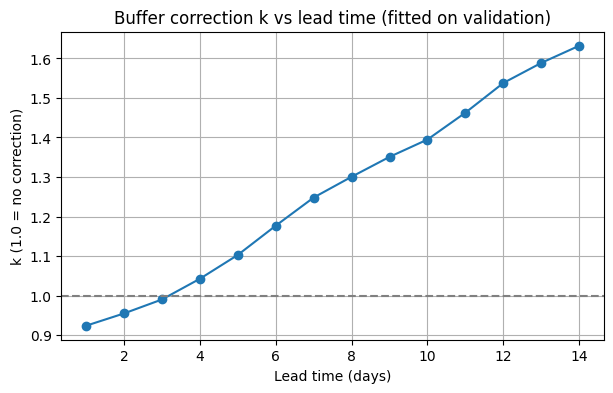

In [53]:
# Step 25: fit k for every lead time (1 to 14) on VALIDATION, check on TEST, and save

rows = []
for L in range(1, 15):
    gv = window_table(m_val, val_pred_clipped, L)    # validation windows (fit k here)
    gt = window_table(m_test, mt["pred"].values, L)  # test windows (honest check)
    k = gv["scaled_miss"].quantile(0.90)
    rows.append([
        L, len(gv), len(gt), k,
        (gv["scaled_miss"] <= 1).mean() * 100,   # validation coverage with no correction
        (gt["scaled_miss"] <= 1).mean() * 100,   # test coverage with no correction
        (gt["scaled_miss"] <= k).mean() * 100,   # test coverage with k
    ])

k_table = pd.DataFrame(rows, columns=[
    "Lead time", "Val windows", "Test windows", "k",
    "Val cov. now %", "Test cov. now %", "Test cov. with k %",
])
print(k_table.round(3).to_string(index=False))

# Save only what a backend would need
k_table[["Lead time", "k"]].to_csv(
    "/content/drive/MyDrive/ML_stockAdvisor_backup/restock_k_factors.csv", index=False)
print()
print("Saved restock_k_factors.csv (target 90%, z = 1.28)")

# Plot k against lead time
plt.figure(figsize=(7, 4))
plt.plot(k_table["Lead time"], k_table["k"], marker="o")
plt.axhline(1.0, color="gray", linestyle="--")
plt.title("Buffer correction k vs lead time (fitted on validation)")
plt.xlabel("Lead time (days)")
plt.ylabel("k (1.0 = no correction)")
plt.grid(True)
plt.show()

In [54]:
%%writefile -a /content/saved_model/forecaster.py


def load_k_table(path):
    # CSV with columns: Lead time, k (fitted for z = 1.28 only)
    return pd.read_csv(path)


def get_k(k_table, lead_time_days, never_shrink=True):
    # Looks up the buffer correction for a lead time; by default never shrinks the buffer
    row = k_table[k_table["Lead time"] == lead_time_days]
    if row.empty:
        raise ValueError("No k factor for this lead time")
    k = float(row["k"].iloc[0])
    return max(k, 1.0) if never_shrink else k


def recommend_restock_v3(forecast, current_stock, lead_time_days, z, error_table,
                         default_error, k_table, on_order=0, never_shrink=True):
    # Per-product safety stock, multiplied by the lead-time correction k
    if abs(z - 1.28) > 1e-9:
        raise ValueError("k factors were fitted for z = 1.28 only; refit them for another z")
    out = recommend_restock_v2(forecast, current_stock, lead_time_days, z, error_table,
                               default_error, on_order)
    k = get_k(k_table, lead_time_days, never_shrink)
    out["k_factor"] = k
    out["safety_stock"] = out["safety_stock"] * k
    need = out["lead_time_demand"] + out["safety_stock"] - out["current_stock"] - out["on_order"]
    out["reorder_qty"] = np.ceil(np.clip(need, 0, None)).astype(int)
    return out

Appending to /content/saved_model/forecaster.py


In [55]:
# Step 26 test: reload the module, check the k logic, back up

import importlib, shutil, os
importlib.reload(forecaster)
backup = "/content/drive/MyDrive/ML_stockAdvisor_backup"

k_loaded = forecaster.load_k_table(backup + "/restock_k_factors.csv")
print("k table rows:", len(k_loaded))

# 1. Module result vs a by-hand calculation in the notebook (lead time 7)
base7 = recommend_restock_v2(fc_file, current_stock, 7, Z, per_combo_error, DAILY_ERROR)
k7 = float(k_loaded.loc[k_loaded["Lead time"] == 7, "k"].iloc[0])
safety7 = base7["safety_stock"] * k7
qty7 = np.ceil(np.clip(base7["lead_time_demand"] + safety7
                       - base7["current_stock"] - base7["on_order"], 0, None)).astype(int)

rec7_mod = forecaster.recommend_restock_v3(fc_file, current_stock, 7, Z, err_loaded,
                                           DAILY_ERROR, k_loaded)
print("Test 1 (lead time 7 matches hand calculation):",
      bool((rec7_mod["reorder_qty"].values == qty7.values).all()))

# 2. For lead time 3, k is below 1, so the buffer must stay unchanged
rec3_mod = forecaster.recommend_restock_v3(fc_file, current_stock, 3, Z, err_loaded,
                                           DAILY_ERROR, k_loaded)
print("Test 2 (lead time 3 identical to version 2):",
      bool((rec3_mod["reorder_qty"].values == rec2["reorder_qty"].values).all()),
      "| k used:", rec3_mod["k_factor"].iloc[0])

# 3. A larger buffer must never lower the order
print("Test 3 (k never lowers the order at lead time 7):",
      bool((rec7_mod["reorder_qty"].values >= base7["reorder_qty"].values).all()))

# 4. Wrong z must be rejected
try:
    forecaster.recommend_restock_v3(fc_file, current_stock, 7, 1.65, err_loaded, DAILY_ERROR, k_loaded)
    print("Test 4: PROBLEM, no error was raised")
except ValueError as e:
    print("Test 4 (z = 1.65 rejected):", e)

# 5. Effect of the correction
print()
print("Lead time 7: reorders", (base7["reorder_qty"] > 0).sum(), "->", (rec7_mod["reorder_qty"] > 0).sum(),
      "| total units", base7["reorder_qty"].sum(), "->", rec7_mod["reorder_qty"].sum(),
      "| k used:", round(rec7_mod["k_factor"].iloc[0], 3))

# 6. The order-list builder must work with the new output
ol7 = forecaster.build_order_list(fc_file, rec7_mod, 7)
print()
print("Priorities at lead time 7 with k:")
print(ol7["priority"].value_counts())

shutil.copy("/content/saved_model/forecaster.py", backup + "/forecaster.py")
print()
print("Backed up. forecaster.py size (KB):", round(os.path.getsize(backup + "/forecaster.py") / 1e3, 2))

k table rows: 14
Test 1 (lead time 7 matches hand calculation): True
Test 2 (lead time 3 identical to version 2): True | k used: 1.0
Test 3 (k never lowers the order at lead time 7): True
Test 4 (z = 1.65 rejected): k factors were fitted for z = 1.28 only; refit them for another z

Lead time 7: reorders 95 -> 95 | total units 46962 -> 49929 | k used: 1.248

Priorities at lead time 7 with k:
priority
URGENT    90
ORDER      5
OK         5
Name: count, dtype: int64

Backed up. forecaster.py size (KB): 6.28


In [56]:
# Step 27: record library versions and list the files to push to Git

import sys
import sklearn, pandas, numpy, joblib, matplotlib
import os

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)
print("joblib:", joblib.__version__)
print("matplotlib:", matplotlib.__version__)

folder = "/content/drive/MyDrive/ML_stockAdvisor_backup"

lines = [
    "scikit-learn==" + sklearn.__version__,
    "pandas==" + pandas.__version__,
    "numpy==" + numpy.__version__,
    "joblib==" + joblib.__version__,
    "matplotlib==" + matplotlib.__version__,
]
with open(folder + "/requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")

print()
print("Files in the backup folder:")
for name in sorted(os.listdir(folder)):
    path = os.path.join(folder, name)
    if os.path.isfile(path):
        print(" ", name, "-", round(os.path.getsize(path) / 1e6, 3), "MB")

Python: 3.13.16
scikit-learn: 1.6.1
pandas: 2.2.3
numpy: 2.1.3
joblib: 1.6.0
matplotlib: 3.10.0

Files in the backup folder:
  demand_forecaster.joblib - 1.452 MB
  expected_forecast.csv - 0.06 MB
  forecaster.py - 0.006 MB
  order_list.csv - 0.004 MB
  per_product_error.csv - 0.003 MB
  requirements.txt - 0.0 MB
  restock_k_factors.csv - 0.0 MB
  sample_history.csv - 0.035 MB
  sample_plan.csv - 0.046 MB
  sample_stock.csv - 0.002 MB
